# 🔎 Notebook 1 — monitoring_sites.csv
**Projet Data Mining — Investigation sur plusieurs datasets**



## Cellule 1 — Imports et chargement


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial import Voronoi, voronoi_plot_2d
from sklearn.cluster import DBSCAN, KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.pairwise import haversine_distances
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

FILENAME = "monitoring_sites.csv"
try:
    from google.colab import files          # on est dans Colab
    if not os.path.exists(FILENAME):
        print("Téléverse le fichier", FILENAME)
        files.upload()
except ImportError:                          # on est en local
    pass

candidates = [FILENAME, "/mnt/user-data/uploads/" + FILENAME]
path = next((p for p in candidates if os.path.exists(p)), None)
assert path is not None, "Fichier introuvable : téléverse monitoring_sites.csv"

raw = pd.read_csv(path)        # copie brute, jamais modifiée
print("Chargé :", raw.shape)
raw.head()

Chargé : (64, 14)


,site_code,site_name,site_category,region,jurisdiction,latitude,longitude,elevation_m,habitat_category,cave_access_category,orchard_context,programme_start_date,programme_end_date,site_status
0,KNT-KES,Kestrel Cavern Monitoring Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.68,112.31,248.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active
1,KNT-LUM,Luma Karst Reserve Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.81,112.44,25.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active
2,KNT-SEN,Senna Ridge Cave Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.59,112.50,45.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active
3,AVL-MAR,Marula East Orchard Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.41,101.69,226.0,durian_orchard,not applicable,commercial or research orchard,2016-01-01,NaN,active
4,AVL-VEL,Velin Basin Orchard Site,orchard monitoring,Eastern Avelora Agricultural Cluster,Avelora Federation,7.55,101.84,24.0,durian_orchard,not applicable,commercial or research orchard,2016-01-01,NaN,active


## Cellule 2 — Structure du dataset


In [ ]:
print("Dimensions :", raw.shape)
print("\nTypes :")
print(raw.dtypes)

print("\nValeurs manquantes :")
na = raw.isna().sum()
print(na[na > 0])

print("\nDoublons (lignes entières) :", raw.duplicated().sum())
print("Doublons sur site_code :", raw.site_code.duplicated().sum())

print("\nNombre de valeurs distinctes par colonne :")
nun = raw.nunique(dropna=False)
print(nun)
print("\nColonnes constantes :", list(nun[nun == 1].index))

Dimensions : (64, 14)

Types :
site_code                object
site_name                object
site_category            object
region                   object
jurisdiction             object
latitude                float64
longitude               float64
elevation_m             float64
habitat_category         object
cave_access_category     object
orchard_context          object
programme_start_date     object
programme_end_date      float64
site_status              object
dtype: object

Valeurs manquantes :
elevation_m            1
programme_end_date    64
dtype: int64

Doublons (lignes entières) : 0
Doublons sur site_code : 0

Nombre de valeurs distinctes par colonne :
site_code               64
site_name               64
site_category            4
region                   3
jurisdiction             3
latitude                64
longitude               64
elevation_m             58
habitat_category         8
cave_access_category     2
orchard_context          2
programme_start_date  

## Cellule 3 — Nettoyage


In [ ]:
sites = raw.copy()

# 1) Casse / espaces
for col in ["site_category", "habitat_category", "cave_access_category", "orchard_context", "region", "jurisdiction"]:
    sites[col] = sites[col].str.strip().str.lower() if col == "site_category" else sites[col].str.strip()

print("site_category avant :", raw.site_category.unique())
print("site_category après :", sites.site_category.unique())

# 2) Altitude manquante : on NE remplit PAS, on la signale
sites["elevation_missing"] = sites.elevation_m.isna()
print("\nSites sans altitude :", sites.loc[sites.elevation_missing, "site_code"].tolist())

# 3) Dates
sites["programme_start_date"] = pd.to_datetime(sites.programme_start_date, errors="coerce")
sites["start_year"] = sites.programme_start_date.dt.year
print("\nAnnée de début de programme :", sites.start_year.value_counts().sort_index().to_dict())
print(pd.crosstab(sites.start_year, sites.site_category))

# 4) Préfixe du code site
sites["prefix"] = sites.site_code.str.split("-").str[0]
print("\nPréfixes :", sites.prefix.value_counts().to_dict())

sites.head(3)

site_category avant : ['cave monitoring' 'orchard monitoring' 'habitat monitoring'
 'ORCHARD MONITORING']
site_category après : ['cave monitoring' 'orchard monitoring' 'habitat monitoring']

Sites sans altitude : ['KNT-CYP']

Année de début de programme : {2016: 27, 2017: 16, 2018: 21}
site_category  cave monitoring  habitat monitoring  orchard monitoring
start_year                                                            
2016                         5                  16                   6
2017                         2                   8                   6
2018                         1                  16                   4

Préfixes : {'KNT': 22, 'AVL': 22, 'TMB': 20}


,site_code,site_name,site_category,region,jurisdiction,latitude,longitude,elevation_m,habitat_category,cave_access_category,orchard_context,programme_start_date,programme_end_date,site_status,elevation_missing,start_year,prefix
0,KNT-KES,Kestrel Cavern Monitoring Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.68,112.31,248.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active,False,2016,KNT
1,KNT-LUM,Luma Karst Reserve Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.81,112.44,25.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active,False,2016,KNT
2,KNT-SEN,Senna Ridge Cave Site,cave monitoring,Kintara Karst Cluster,Kintara Republic,4.59,112.50,45.0,karst_habitat,managed,none recorded,2016-01-01,NaN,active,False,2016,KNT


## Cellule 4 — Cohérence interne : les colonnes se contredisent-elles ?


In [ ]:
print("=== Catégorie de site x habitat ===")
print(pd.crosstab(sites.site_category, sites.habitat_category))

print("\n=== Région x catégorie de site ===")
print(pd.crosstab(sites.region, sites.site_category))

print("\n=== Préfixe du code x région (doit être une bijection) ===")
print(pd.crosstab(sites.prefix, sites.region))

# Altitudes exactement identiques
vc = sites.elevation_m.value_counts()
print("\nAltitudes répétées :", vc[vc > 1].to_dict())
plateau = sites[sites.elevation_m == 5.0][["site_code", "site_category", "habitat_category", "region"]]
print("\nSites à altitude exactement 5.0 m :")
print(plateau)

# Précision des coordonnées (nombre de décimales de la latitude saisie)
def n_dec(x):
    s = f"{x:.6f}".rstrip("0")
    return len(s.split(".")[1]) if "." in s else 0

sites["dec_lat"] = sites.latitude.map(n_dec)
sites["dec_lon"] = sites.longitude.map(n_dec)
sites["row_rank"] = np.arange(len(sites))
print("\nDécimales des coordonnées pour les 12 premières lignes :")
print(sites.loc[:11, ["site_code", "latitude", "longitude", "dec_lat", "dec_lon"]])
print("\nSites avec au plus 2 décimales sur lat ET lon :")
print(sites[(sites.dec_lat <= 2) & (sites.dec_lon <= 2)][["row_rank", "site_code", "site_category"]])

=== Catégorie de site x habitat ===
habitat_category    coastal_habitat  degraded_land  durian_orchard  karst_habitat  mixed_agriculture  mixed_forest  protected_forest  research_site
site_category                                                                                                                                      
cave monitoring                   1              0               0              7                  0             0                 0              0
habitat monitoring                9              2               0              2                  0            19                 3              5
orchard monitoring                0              0              10              0                  5             0                 0              1

=== Région x catégorie de site ===
site_category                         cave monitoring  habitat monitoring  orchard monitoring
region                                                                                       


### Interprétation des résultats

Faits observés :
- Les cavernes sont principalement à Kintara et les vergers à Avelora. Seule Tembara possède les deux.
- TMB-NAC est la seule caverne en zone côtière.
- KNT-CHP et KNT-QWU sont des sites karstiques, mais pas des cavernes.
- Sept sites ont une altitude exacte de 5 m, probablement une valeur arrondie ou minimale.
- Les coordonnées des 8 premiers sites sont moins précises que celles des autres.



## Cellule 5 — Statistiques descriptives et visualisations


count     63.0
mean     147.9
std       97.1
min        5.0
25%       82.1
50%      142.4
75%      223.3
max      418.8
Name: elevation_m, dtype: float64

Médiane : 142.4 | Moyenne : 147.9 | Écart-type : 97.1
Asymétrie (skew) : 0.28

Altitude par région :
                                      count   mean   std   min    25%    50%    75%    max
region                                                                                    
Eastern Avelora Agricultural Cluster   22.0  158.3  86.8   5.0  100.8  159.4  231.2  314.3
Kintara Karst Cluster                  21.0  187.1  94.4  25.0  118.2  190.4  237.8  418.8
Tembara Coastal Cluster                20.0   95.2  91.2   5.0    5.0   87.9  130.8  299.0

Altitude par catégorie de site :
                    count   mean    std   min   25%    50%    75%    max
site_category                                                           
cave monitoring       7.0  160.8  100.3  25.0  91.5  179.5  219.6  299.0
habitat monitoring   40.0  147.3  10

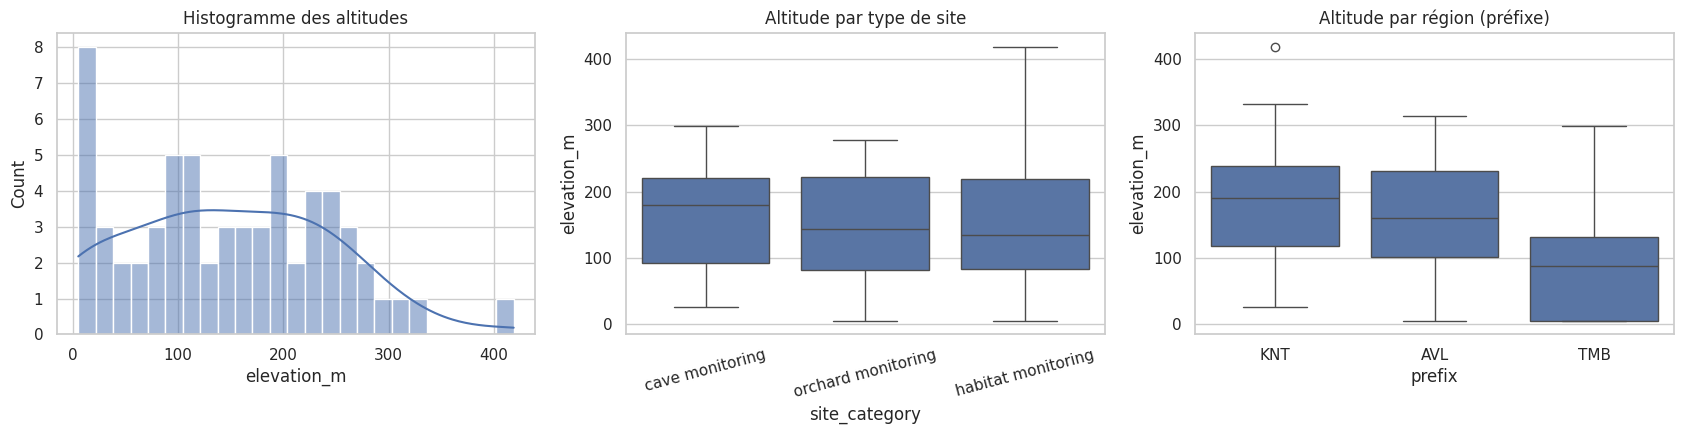

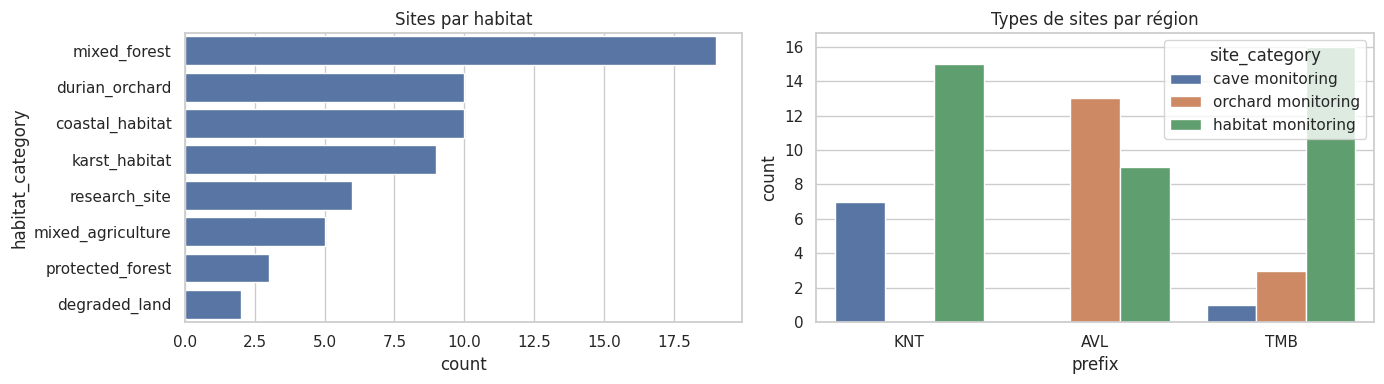

In [ ]:
elev = sites.elevation_m
print(elev.describe().round(1))
print("\nMédiane :", elev.median(), "| Moyenne :", round(elev.mean(), 1), "| Écart-type :", round(elev.std(), 1))
print("Asymétrie (skew) :", round(elev.skew(), 2))

print("\nAltitude par région :")
print(sites.groupby("region").elevation_m.describe().round(1))
print("\nAltitude par catégorie de site :")
print(sites.groupby("site_category").elevation_m.describe().round(1))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(sites.elevation_m, bins=25, kde=True, ax=ax[0])
ax[0].set_title("Histogramme des altitudes")
sns.boxplot(data=sites, x="site_category", y="elevation_m", ax=ax[1])
ax[1].set_title("Altitude par type de site"); ax[1].tick_params(axis="x", rotation=15)
sns.boxplot(data=sites, x="prefix", y="elevation_m", ax=ax[2])
ax[2].set_title("Altitude par région (préfixe)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=sites, y="habitat_category", order=sites.habitat_category.value_counts().index, ax=ax[0])
ax[0].set_title("Sites par habitat")
sns.countplot(data=sites, x="prefix", hue="site_category", ax=ax[1])
ax[1].set_title("Types de sites par région")
plt.tight_layout(); plt.show()

### Interprétation (cellule 5)
L’altitude varie de 5 à 419 m, avec une moyenne de 148 m et une médiane de 142 m. La distribution est plutôt symétrique.



On remarque un petit regroupement à 5 m, correspondant aux 7 sites déjà identifiés en cellule 4.



Les altitudes semblent assez similaires entre les cavernes, les vergers et les habitats. Attention toutefois, car les cavernes sont peu nombreuses.



À Tembara, les altitudes sont très dispersées malgré son classement en région côtière. Ce point mérite une vérification avec la carte et les clusters.

## Cellule 6 — Carte des sites


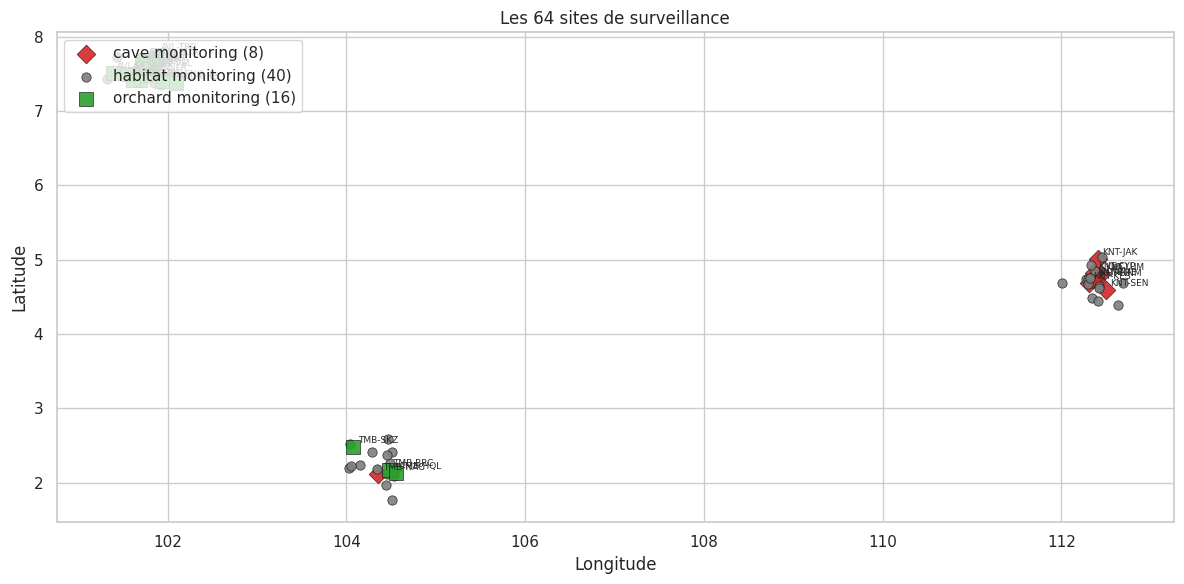

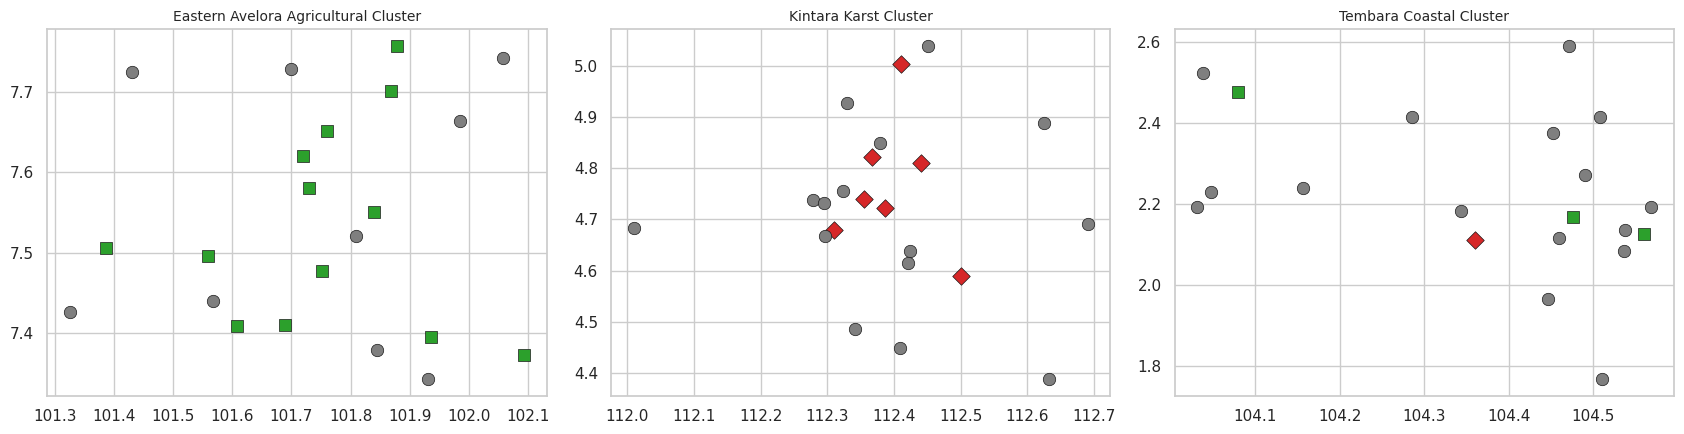

In [ ]:
markers = {"cave monitoring": "D", "orchard monitoring": "s", "habitat monitoring": "o"}
colors = {"cave monitoring": "#d62728", "orchard monitoring": "#2ca02c", "habitat monitoring": "#7f7f7f"}

fig, ax = plt.subplots(figsize=(12, 6))
for cat, g in sites.groupby("site_category"):
    ax.scatter(g.longitude, g.latitude, marker=markers[cat], c=colors[cat], s=90 if cat != "habitat monitoring" else 45,
               edgecolor="k", linewidth=.5, label=f"{cat} ({len(g)})", alpha=.9)
for _, r in sites[sites.site_category != "habitat monitoring"].iterrows():
    ax.annotate(r.site_code, (r.longitude, r.latitude), fontsize=6.5, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.legend(loc="upper left")
ax.set_title("Les 64 sites de surveillance")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, (reg, g) in zip(ax, sites.groupby("region")):
    for cat, gg in g.groupby("site_category"):
        a.scatter(gg.longitude, gg.latitude, marker=markers[cat], c=colors[cat], s=80, edgecolor="k", linewidth=.5)
    a.set_title(reg, fontsize=10)
plt.tight_layout(); plt.show()

Trois groupes géographiques bien distincts apparaissent : Kintara (4,4–5,0°N / 112°E), Avelora (7,3–7,8°N / 101–102°E) et Tembara (1,8–2,6°N / 104°E).



Les 7 cavernes de Kintara sont concentrées dans une même zone, sans verger à proximité.



Le dataset semble organisé en trois groupes d'étude : Kintara, principalement composé de cavernes ; Avelora, composé de vergers ; et Tembara, qui regroupe les deux types de sites.





## Cellule 7 — Distances géographiques (Haversine)


In [ ]:
R = 6371.0
coords_rad = np.radians(sites[["latitude", "longitude"]].to_numpy())
D = haversine_distances(coords_rad) * R          # matrice 64 x 64 en km
D_df = pd.DataFrame(D, index=sites.site_code, columns=sites.site_code)

caves = sites.index[sites.site_category == "cave monitoring"]
orchs = sites.index[sites.site_category == "orchard monitoring"]

cave_orch = pd.DataFrame(D[np.ix_(orchs, caves)],
                         index=sites.site_code[orchs], columns=sites.site_code[caves]).round(0)
print("Distance verger -> caverne (km) :")
print(cave_orch)

print("\nDistance minimale à une caverne, par verger :")
print(cave_orch.min(axis=1).sort_values().round(0))

print("\nDistance minimale entre régions (km) :")
for a in sites.region.unique():
    for b in sites.region.unique():
        if a < b:
            ia = sites.index[sites.region == a]; ib = sites.index[sites.region == b]
            print(f"  {a[:18]:<18} <-> {b[:18]:<18} : {D[np.ix_(ia, ib)].min():.0f} km")

# Distance au plus proche voisin (tous sites)
Dn = D + np.eye(len(D)) * 1e9
sites["nn_km"] = Dn.min(axis=1)
print("\nDistance au plus proche voisin :")
print(sites.groupby("region").nn_km.describe().round(1))

Distance verger -> caverne (km) :
site_code  KNT-KES  KNT-LUM  KNT-SEN  TMB-NAC  KNT-CYP  KNT-NNM  KNT-JAK  KNT-BME
site_code                                                                        
AVL-MAR     1213.0   1223.0   1236.0    659.0   1215.0   1220.0   1215.0   1216.0
AVL-VEL     1201.0   1211.0   1224.0    666.0   1203.0   1207.0   1202.0   1204.0
AVL-ORR     1215.0   1225.0   1238.0    679.0   1217.0   1222.0   1217.0   1218.0
AVL-TRP     1203.0   1212.0   1226.0    685.0   1204.0   1209.0   1203.0   1205.0
AVL-NFR     1208.0   1218.0   1231.0    663.0   1210.0   1215.0   1210.0   1211.0
AVL-GRB     1169.0   1179.0   1192.0    637.0   1171.0   1176.0   1170.0   1172.0
AVL-ECJ     1248.0   1258.0   1271.0    684.0   1250.0   1255.0   1250.0   1251.0
AVL-RBC     1229.0   1239.0   1252.0    675.0   1231.0   1236.0   1231.0   1232.0
AVL-KAR     1222.0   1232.0   1244.0    663.0   1224.0   1228.0   1224.0   1225.0
AVL-YAU     1212.0   1222.0   1235.0    680.0   1214.0   1219.0 

### Interprétation (cellule 7)

- TMB-NAC est la seule caverne située à proximité de vergers : TMB-BRC (14 km), TMB-HQL (22 km) et TMB-SKZ (51 km).
- Les vergers d'Avelora sont beaucoup plus éloignés : environ 640 à 690 km de TMB-NAC et plus de 1 150 km des cavernes de Kintara.
- Les trois régions sont géographiquement isolées les unes des autres.
- Il sera donc difficile d'établir un lien statistique fiable entre les cavernes et les vergers, car leur répartition géographique est liée au type de site.


## Cellule 8 — Tessellation de Voronoï


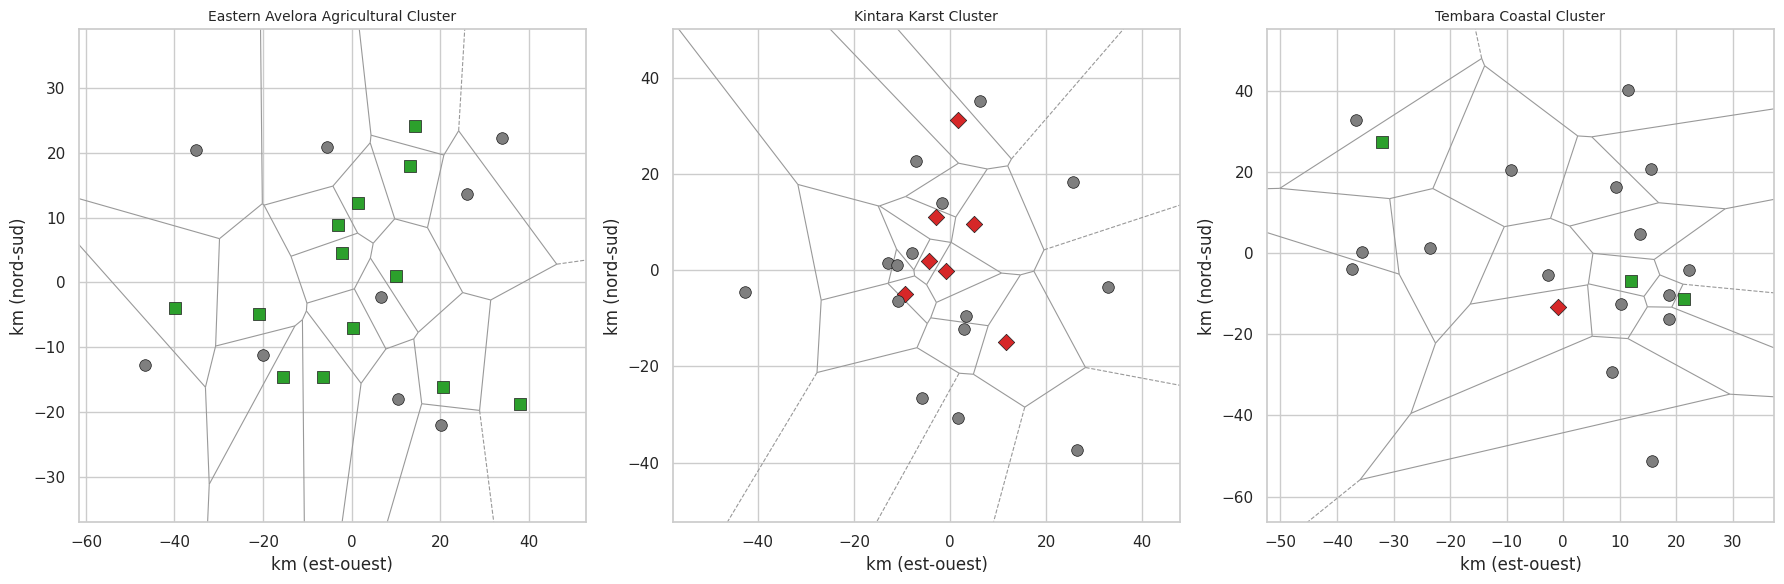

Cellules fermées (km²), les 8 plus grandes :
   site_code                                region  cell_km2
22   KNT-JAK                 Kintara Karst Cluster    9147.0
39   TMB-GZX               Tembara Coastal Cluster    5115.0
27   KNT-GGN                 Kintara Karst Cluster    3767.0
8    AVL-KAR  Eastern Avelora Agricultural Cluster    3557.0
4    AVL-HTY  Eastern Avelora Agricultural Cluster    2264.0
34   TMB-CKU               Tembara Coastal Cluster     939.0
44   TMB-QCB               Tembara Coastal Cluster     609.0
5    AVL-RNY  Eastern Avelora Agricultural Cluster     554.0

Note : les sites en bordure ont des cellules ouvertes (non calculables) ; ce sont souvent les plus isolés.


In [ ]:
def km_xy(g):
    lat0 = np.radians(g.latitude.mean())
    x = (g.longitude - g.longitude.mean()) * 111.32 * np.cos(lat0)
    y = (g.latitude - g.latitude.mean()) * 111.32
    return np.c_[x, y]

def poly_area(poly):
    x, y = poly[:, 0], poly[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
areas = []
for ax, (reg, g) in zip(axes, sites.groupby("region")):
    P = km_xy(g)
    vor = Voronoi(P)
    voronoi_plot_2d(vor, ax=ax, show_vertices=False, show_points=False, line_colors="#999", line_width=.8)
    for cat, gg in g.groupby("site_category"):
        idx = [g.index.get_loc(i) for i in gg.index]
        ax.scatter(P[idx, 0], P[idx, 1], c=colors[cat], marker=markers[cat], s=70, edgecolor="k", linewidth=.5, zorder=3)
    ax.set_xlim(P[:, 0].min() - 15, P[:, 0].max() + 15); ax.set_ylim(P[:, 1].min() - 15, P[:, 1].max() + 15)
    ax.set_title(reg, fontsize=10); ax.set_xlabel("km (est-ouest)"); ax.set_ylabel("km (nord-sud)")
    # Aires des cellules fermées
    for i, reg_idx in enumerate(vor.point_region):
        region = vor.regions[reg_idx]
        if -1 not in region and len(region) > 2:
            areas.append((g.site_code.iloc[i], reg, poly_area(vor.vertices[region])))
plt.tight_layout(); plt.show()

areas = pd.DataFrame(areas, columns=["site_code", "region", "cell_km2"])
print("Cellules fermées (km²), les 8 plus grandes :")
print(areas.sort_values("cell_km2", ascending=False).head(8).round(0))
print("\nNote : les sites en bordure ont des cellules ouvertes (non calculables) ; ce sont souvent les plus isolés.")

### Interprétation (cellule 8)

- Les cellules les plus grandes correspondent aux sites les plus isolés.
- Les cellules ouvertes concernent les sites situés en bordure du nuage, qui n'ont pas de voisins de tous les côtés.

## Cellule 9 — Clustering spatial (DBSCAN et k-means)


In [ ]:
X_rad = np.radians(sites[["latitude", "longitude"]].to_numpy())

print("Balayage de eps (DBSCAN, Haversine, min_samples=3)")
rows = []
for eps_km in [10, 15, 20, 30, 40, 60]:
    lab = DBSCAN(eps=eps_km / R, min_samples=3, metric="haversine").fit(X_rad).labels_
    rows.append({"eps_km": eps_km, "n_clusters": len(set(lab)) - (1 if -1 in lab else 0), "n_bruit": int((lab == -1).sum())})
print(pd.DataFrame(rows))

# eps = 60 km : retrouve-t-on les régions ?
sites["db60"] = DBSCAN(eps=60 / R, min_samples=3, metric="haversine").fit(X_rad).labels_
print("\nDBSCAN eps=60 km vs région :")
print(pd.crosstab(sites.db60, sites.region))

# eps = 20 km : sous-structures ?
sites["db20"] = DBSCAN(eps=20 / R, min_samples=3, metric="haversine").fit(X_rad).labels_
print("\nDBSCAN eps=20 km (clusters internes) :")
print(pd.crosstab(sites.db20, sites.region))
print("\nSites en bruit à 20 km :")
print(sites.loc[sites.db20 == -1, ["site_code", "site_category", "habitat_category", "nn_km"]].round(1))

# k-means
km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(sites[["latitude", "longitude"]])
print("\nAdjusted Rand Index k-means(k=3) vs région :", round(adjusted_rand_score(sites.region, km.labels_), 3))

Balayage de eps (DBSCAN, Haversine, min_samples=3)
   eps_km  n_clusters  n_bruit
0      10           6       35
1      15           4       16
2      20           4        8
3      30           3        1
4      40           3        0
5      60           3        0

DBSCAN eps=60 km vs région :
region  Eastern Avelora Agricultural Cluster  Kintara Karst Cluster  Tembara Coastal Cluster
db60                                                                                        
0                                          0                     22                        0
1                                         22                      0                        0
2                                          0                      0                       20

DBSCAN eps=20 km (clusters internes) :
region  Eastern Avelora Agricultural Cluster  Kintara Karst Cluster  Tembara Coastal Cluster
db20                                                                                        
-1         

### Interprétation (cellule 9)

- Pour un eps entre 30 et 60 km, DBSCAN identifie exactement 3 clusters, correspondant aux trois régions, avec très peu de bruit. K-means retrouve les mêmes groupes (ARI = 1).
- Avec un eps de 20 km, plusieurs sites sont considérés comme du bruit, principalement à cause de leur isolement ou du manque de voisins proches.
- Les deux algorithmes donnent les mêmes résultats, ce qui renforce la fiabilité du regroupement.


## Cellule 10 — Détection d'anomalies (IQR, LOF, Isolation Forest)


IQR : bornes [-129.7 ; 435.1] -> 0 valeur(s) aberrante(s)

--- Top 6 LOF multivarié ---
   site_code       site_category habitat_category  elevation_m  lof_multi
15   KNT-CHP  habitat monitoring    karst_habitat        418.8       3.04
6    TMB-NAC     cave monitoring  coastal_habitat        299.0       2.00
23   KNT-VXR  habitat monitoring     mixed_forest        332.8       1.93
7    TMB-PEL  habitat monitoring  coastal_habitat        261.0       1.74
1    KNT-LUM     cave monitoring    karst_habitat         25.0       1.57
51   TMB-BRC  orchard monitoring   durian_orchard        220.6       1.48

--- Top 6 Isolation Forest ---
   site_code       site_category habitat_category  elevation_m  iso_score
15   KNT-CHP  habitat monitoring    karst_habitat        418.8       0.68
29   AVL-ARU  habitat monitoring    research_site        314.3       0.60
6    TMB-NAC     cave monitoring  coastal_habitat        299.0       0.58
23   KNT-VXR  habitat monitoring     mixed_forest        332.8    

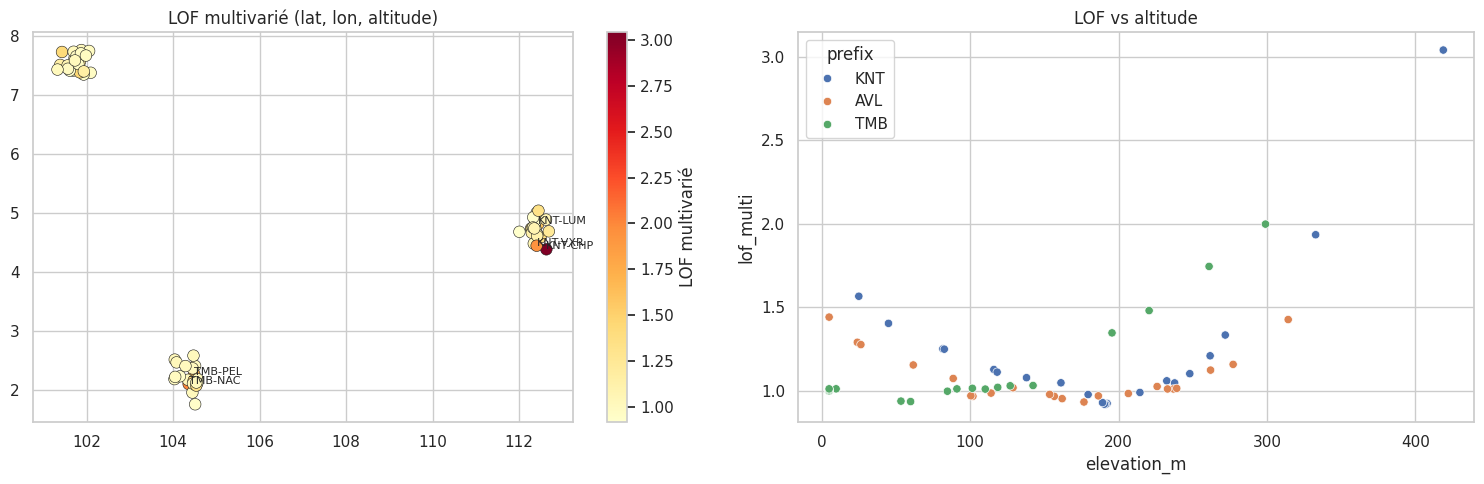

In [ ]:
# 1) IQR sur l'altitude
e = sites.elevation_m.dropna()
q1, q3 = e.quantile([.25, .75]); iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
sites["out_iqr"] = (sites.elevation_m < low) | (sites.elevation_m > high)
print(f"IQR : bornes [{low:.1f} ; {high:.1f}] -> {sites.out_iqr.sum()} valeur(s) aberrante(s)")

# 2) Variables standardisées (altitude manquante -> médiane, uniquement pour CE calcul)
Z = sites[["latitude", "longitude", "elevation_m"]].copy()
Z["elevation_m"] = Z.elevation_m.fillna(Z.elevation_m.median())
Z = StandardScaler().fit_transform(Z)

lof = LocalOutlierFactor(n_neighbors=8).fit(Z)
sites["lof_multi"] = -lof.negative_outlier_factor_

iso = IsolationForest(n_estimators=300, contamination=0.05, random_state=0).fit(Z)
sites["iso_score"] = -iso.score_samples(Z)           # plus grand = plus anormal

lof_sp = LocalOutlierFactor(n_neighbors=5, metric="precomputed").fit(D)
sites["lof_spatial"] = -lof_sp.negative_outlier_factor_

cols = ["site_code", "site_category", "habitat_category", "elevation_m"]
print("\n--- Top 6 LOF multivarié ---");  print(sites.nlargest(6, "lof_multi")[cols + ["lof_multi"]].round(2))
print("\n--- Top 6 Isolation Forest ---"); print(sites.nlargest(6, "iso_score")[cols + ["iso_score"]].round(2))
print("\n--- Top 6 LOF spatial (Haversine) ---"); print(sites.nlargest(6, "lof_spatial")[cols + ["lof_spatial"]].round(2))

# 3) Consensus : combien de méthodes classent le site dans son top 6 ?
top = 6
flags = pd.DataFrame({
    "lof_multi": sites.lof_multi.rank(ascending=False) <= top,
    "iso": sites.iso_score.rank(ascending=False) <= top,
    "lof_spatial": sites.lof_spatial.rank(ascending=False) <= top,
})
sites["n_flags"] = flags.sum(axis=1)
print("\n=== Sites signalés par au moins 2 méthodes ===")
print(sites[sites.n_flags >= 2][cols + ["lof_multi", "iso_score", "lof_spatial", "n_flags"]].round(2))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sc = ax[0].scatter(sites.longitude, sites.latitude, c=sites.lof_multi, cmap="YlOrRd", s=70, edgecolor="k", linewidth=.4)
plt.colorbar(sc, ax=ax[0], label="LOF multivarié"); ax[0].set_title("LOF multivarié (lat, lon, altitude)")
for _, r in sites.nlargest(5, "lof_multi").iterrows():
    ax[0].annotate(r.site_code, (r.longitude, r.latitude), fontsize=8)
sns.scatterplot(data=sites, x="elevation_m", y="lof_multi", hue="prefix", ax=ax[1])
ax[1].set_title("LOF vs altitude")
plt.tight_layout(); plt.show()

### Interprétation (cellule 10)

- L'IQR ne détecte aucune altitude aberrante, contrairement aux méthodes multivariées LOF et Isolation Forest.
- Quatre sites sont repérés par au moins deux méthodes : KNT-CHP, TMB-NAC, KNT-VXR et TMB-UVF.
- KNT-CHP est particulièrement intéressant : il possède l'altitude la plus élevée (418,8 m), mais n'est pas classé comme caverne.
- TMB-NAC présente également un profil atypique : une caverne située à 299 m dans une région côtière.
- Le LOF spatial repère surtout les sites isolés géographiquement, comme KNT-YRX et TMB-UVF.
- Ces résultats permettent d'identifier quelques sites à examiner dans les prochains notebooks

## Cellule 11 — Autocorrélation spatiale

GLOBAL  : I = 0.070 | attendu sous hasard = -0.016 | p = 0.333

Par région :
  Kintara Karst Cluster          I = -0.056 | attendu = -0.048 | p = 0.673
  Eastern Avelora Agricultural C I = +0.003 | attendu = -0.048 | p = 0.980
  Tembara Coastal Cluster        I = -0.069 | attendu = -0.053 | p = 0.632


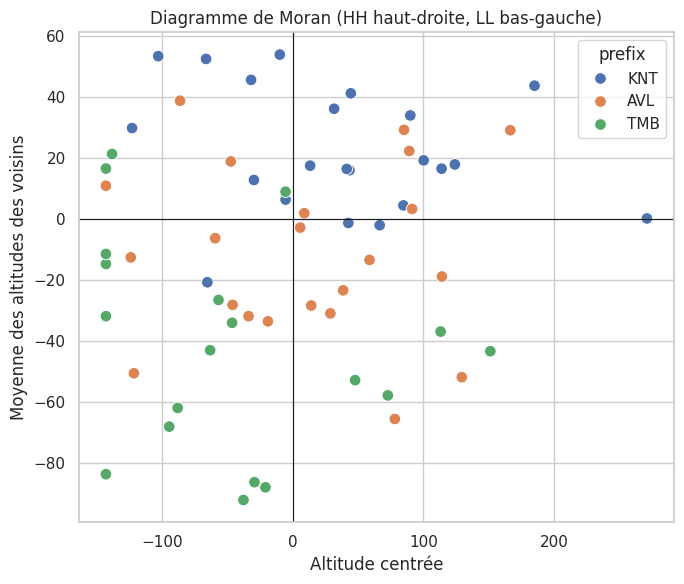


Répartition des quadrants : {'LL': 20, 'HH': 17, 'HL': 14, 'LH': 13}

Sites 'HL' (haut entouré de bas) : ['AVL-MAR', 'AVL-ORR', 'TMB-NAC', 'TMB-PEL', 'KNT-JQG', 'KNT-DMJ', 'AVL-GRB', 'AVL-DER', 'AVL-KAR', 'AVL-ABG', 'AVL-FNM', 'AVL-FNQ', 'TMB-BRC', 'TMB-WST']


In [ ]:
def knn_weights(Dmat, k=5):
    n = len(Dmat)
    W = np.zeros((n, n))
    Dm = Dmat + np.eye(n) * 1e9
    for i in range(n):
        W[i, np.argsort(Dm[i])[:k]] = 1
    return W

def morans_I(y, W, n_perm=999, seed=0):
    y = np.asarray(y, float); n = len(y); z = y - y.mean()
    def I_of(zz):
        return n / (zz ** 2).sum() * (W * np.outer(zz, zz)).sum() / W.sum()
    obs = I_of(z)
    rng = np.random.default_rng(seed)
    sims = np.array([I_of(rng.permutation(z)) for _ in range(n_perm)])
    p = (1 + (np.abs(sims) >= abs(obs)).sum()) / (n_perm + 1)
    return obs, -1 / (n - 1), p

y_all = sites.elevation_m.fillna(sites.elevation_m.median())   # imputation uniquement pour ce calcul

W = knn_weights(D, k=5)
I, EI, p = morans_I(y_all, W)
print(f"GLOBAL  : I = {I:.3f} | attendu sous hasard = {EI:.3f} | p = {p:.3f}")

print("\nPar région :")
for reg in sites.region.unique():
    ix = sites.index[sites.region == reg]
    I, EI, p = morans_I(y_all[ix], knn_weights(D[np.ix_(ix, ix)], 5))
    print(f"  {reg[:30]:<30} I = {I:+.3f} | attendu = {EI:+.3f} | p = {p:.3f}")

# Diagramme de Moran (altitude centrée vs moyenne des voisins)
z = (y_all - y_all.mean()).to_numpy()
Wr = W / W.sum(axis=1, keepdims=True)
lag = Wr @ z
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(x=z, y=lag, hue=sites.prefix, s=70, ax=ax)
ax.axhline(0, c="k", lw=.8); ax.axvline(0, c="k", lw=.8)
ax.set_xlabel("Altitude centrée"); ax.set_ylabel("Moyenne des altitudes des voisins")
ax.set_title("Diagramme de Moran (HH haut-droite, LL bas-gauche)")
plt.tight_layout(); plt.show()

# Quadrants (version simplifiée de LISA, sans test de signifiance local)
quad = np.select([(z > 0) & (lag > 0), (z < 0) & (lag < 0), (z > 0) & (lag < 0), (z < 0) & (lag > 0)],
                 ["HH", "LL", "HL", "LH"], default="NA")
sites["moran_quadrant"] = quad
print("\nRépartition des quadrants :", pd.Series(quad).value_counts().to_dict())
print("\nSites 'HL' (haut entouré de bas) :", sites.loc[sites.moran_quadrant == "HL", "site_code"].tolist())

### Interprétation (cellule 11)

- Le Moran global et les résultats par région ne sont pas significatifs. Les altitudes ne présentent donc pas de structure spatiale particulière.
- Les quadrants du diagramme de Moran sont répartis de manière assez équilibrée, ce qui confirme l'absence de regroupement évident entre sites voisins.
- Cela peut suggérer que les altitudes ont été générées indépendamment de la position géographique, mais ce n'est qu'une hypothèse.
- La géographie semble donc moins intéressante que les séries temporelles pour rechercher des relations dans les données.



## Cellule 12 — Export de la table nettoyée




In [ ]:
export_cols = ["site_code", "site_name", "site_category", "region", "jurisdiction", "latitude", "longitude",
               "elevation_m", "elevation_missing", "habitat_category", "cave_access_category", "orchard_context",
               "prefix", "nn_km", "db20", "lof_multi", "iso_score", "lof_spatial", "n_flags", "moran_quadrant"]
out = sites[export_cols].copy()
out.to_csv("sites_clean.csv", index=False)
print("Sauvegardé : sites_clean.csv", out.shape)

try:
    from google.colab import files
    files.download("sites_clean.csv")
except ImportError:
    pass

Sauvegardé : sites_clean.csv (64, 20)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>